# Homework 7

## Your Name Here (or your names here if you are pair programming)

Student Name: Eduardo Borges Issa

Student UT EID: eb34276

---

Partner Name:

Partner UT EID:

---

Date Created: 10/30/2026

Date Last Modified: 10/30/2026

---

Totoal Points 20. 



## Supprt Vector Machine 

In [1]:
# Standard Headers
# You are welcome to add additional headers here if you wish
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Enable inline mode for matplotlib so that Jupyter displays graphs
%matplotlib inline

# Your allowed to use only the above libraries that are imported. No other libs should be used in this assignment. 

## Heart Dataset 

In this Assignment we will work with some patients dataset. 

We have access to 303 patients data. The features are listed below. 

In [2]:
# Your code here
heart_df = pd.read_csv("Heart.csv")
heart_df

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,Target
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,typical,110,264,0,0,132,0,1.2,2,0.0,reversable,Yes
299,68,1,asymptomatic,144,193,1,0,141,0,3.4,2,2.0,reversable,Yes
300,57,1,asymptomatic,130,131,0,0,115,1,1.2,2,1.0,reversable,Yes
301,57,0,nontypical,130,236,0,2,174,0,0.0,2,1.0,normal,Yes


**Age:** The person’s age in years

**Sex:** The person’s sex (1 = male, 0 = female)

**ChestPain:** chest pain type

* Value 0: asymptomatic
* Value 1: atypical angina
* Value 2: non-anginal pain
* Value 3: typical angina

**RestBP:** The person’s resting blood pressure (mm Hg on admission to the hospital)

**Chol:** The person’s cholesterol measurement in mg/dl

**Fbs:** The person’s fasting blood sugar (> 120 mg/dl, 1 = true; 0 = false)
restecg: resting electrocardiographic results

* Value 0: showing probable or definite left ventricular hypertrophy by Estes’ criteria
* Value 1: normal
* Value 2: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)

**RestECG:** The person’s maximum heart rate achieved

**MaxHR:** Exercise induced angina (1 = yes; 0 = no)

**Oldpeak:** ST depression induced by exercise relative to rest (‘ST’ relates to positions on the ECG plot. See more here)

**Slope:** the slope of the peak exercise ST segment — 0: downsloping; 1: flat; 2: upsloping

* 0: downsloping; 
* 1: flat; 
* 2: upsloping

**Ca:** The number of major vessels (0–3)

**Thal:** A blood disorder called thalassemia Value 0: NULL (dropped from the dataset previously

* Value 1: fixed defect (no blood flow in some part of the heart)
* Value 2: normal blood flow
* Value 3: reversible defect (a blood flow is observed but it is not normal)

**Target:** Heart disease (1 = no, 0= yes)

# Task - 1 Implement SVM using libraries (4 points)
We want to use **Suppert Vector Machine** to perdict if the patients will have heart problems or not. The column "Target" in our datasets includes data about heart diseases. If the patient had heart disease we have a 1 and if not a zero. 

Prepare your data set for predicting heart disease ("Target" column) out of 3 features:

* Age of the patient (Column **"Age"**)
* Gender of the patient (male or female - Column **"Sex"**)
* Cholestrol level of the patient (Column **"Chol"**) 


Split your data into 80% traning data and 20% test data, and implement Support Vector Machine using Scikit-Learn. 





In [35]:
# Add your code Here! 
#scikitlearn imports
from sklearn.model_selection import train_test_split 
from sklearn.svm import SVC

# Prepare data
features = ['Age', 'Sex', 'Chol'] 
target = 'Target' 
heart_df = heart_df.dropna(subset=features + [target]) 
X = heart_df[features].values 
y = heart_df[target].values 

heart_df['Target'] = np.where(heart_df['Target'].astype(str).str.strip().isin(['Yes', '1', '1.0']), 1, 0)
X = heart_df[features].values 
y = heart_df['Target'].values

# 80/20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

# SVM usign scikit-learn
svm_model = SVC(kernel='linear') 
svm_model.fit(X_train, y_train)

# Predic
y_pred_svm = svm_model.predict(X_test) 

print(y_pred_svm)

[1 0 1 1 0 0 1 1 0 1 1 0 1 1 1 0 0 0 1 0 1 0 1 0 1 0 0 1 0 0 0 1 0 1 1 0 1
 1 1 0 1 0 1 1 0 1 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0]


# Task 2 - (4 points)

Cacluate the accuracy, Precision, Recall and F1 score of your **SVM** implementaion from Task 1. 
Print the results. 

You may use library methods for this task if you choose to.


In [51]:
# Add your code Here! 
tp = np.sum((y_pred_svm == 1) & (y_test == 1))
tn = np.sum((y_pred_svm == 0) & (y_test == 0))
fp = np.sum((y_pred_svm == 1) & (y_test == 0))
fn = np.sum((y_pred_svm == 0) & (y_test == 1))

accuracy = (tp + tn)/ (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0 
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0 
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

print("Performance Metrics")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Performance Metrics
Accuracy: 0.5737704918032787
Precision: 0.6071428571428571
Recall: 0.53125
F1 Score: 0.5666666666666667


# Task 3 - Implement SVM without using libraries  - (4 points)

Implement SVM from scratch using Hinge Loss function and Gradient Descent. 
Try to produce the same result as you get from the libraries. 


* Do as many iterations as needed 
* Do maximum **100 iterations**
* Use a very small learning rate for checking your GD implementation. 
* Your are allowed to use your choice of learning rate, like using 0.0001, 0.001 or 0.01 or 0.1 or higher. 
* Visualize your costs. 
* No need to add an y-intercept in this task. 
* You can use libraries to report accuracy, Precision, Recall and F1. 



Final weights: [0.51268722 0.77872318 0.28147254]
Final cost: 0.7449052129185478


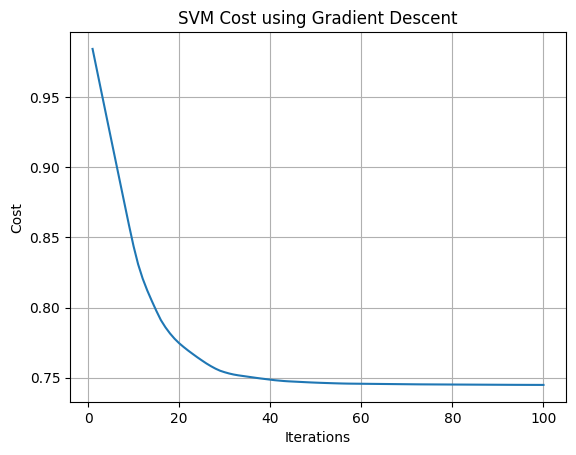

Performance Metrics
Accuracy: 0.5409836065573771
Precision: 0.5555555555555556
Recall: 0.625
F1 Score: 0.5882352941176471


In [66]:
# Calculate mean and standard deviation
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
std[std == 0] = 1

# Standardize data
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std
y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

# Initialize hyperparameters 
learning_rate = 0.1
lambda_param = 0.01
iterations = 100

w = np.zeros(X_train_scaled.shape[1])
costs = []
n = X_train_scaled.shape[0]

# Gradient Descent
for i in range(iterations):
    predictions = np.dot(X_train_scaled, w)
    margins = y_train_svm * predictions
    misclassified = margins < 1
    dw = lambda_param * w
    dw -= np.dot(X_train_scaled[misclassified].T, y_train_svm[misclassified]) / n
    w = w - learning_rate * dw
    # Calculate cost
    predictions = np.dot(X_train_scaled, w)
    hinge_loss = np.maximum(0, 1 - y_train_svm * predictions)
    cost = (lambda_param / 2) * np.dot(w, w) + np.mean(hinge_loss)
    costs.append(cost)
print("Final weights:", w)
print("Final cost:", costs[-1])

# plot
plt.plot(range(1, iterations + 1), costs)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("SVM Cost using Gradient Descent")
plt.grid(True)
plt.show()

# Performance
predictions = np.dot(X_test_scaled, w)
y_pred_scratch = np.where(predictions >= 0, 1, 0)

tp = np.sum((y_test == 1) & (y_pred_scratch == 1))
tn = np.sum((y_test == 0) & (y_pred_scratch == 0))
fp = np.sum((y_test == 0) & (y_pred_scratch == 1))
fn = np.sum((y_test == 1) & (y_pred_scratch == 0))

accuracy_scratch = (tp + tn)/ (tp + tn + fp + fn)
precision_scratch = tp / (tp + fp) if (tp + fp) > 0 else 0.0 
recall_scratch = tp / (tp + fn) if (tp + fn) > 0 else 0.0 
f1_scratch = 2 * (precision_scratch * recall_scratch) / (precision_scratch + recall_scratch) if (precision_scratch + recall_scratch) > 0 else 0.0

print("Performance Metrics")
print("Accuracy:", accuracy_scratch)
print("Precision:", precision_scratch)
print("Recall:", recall_scratch)
print("F1 Score:", f1_scratch)

# Task 4 - Compare SVM results with Logistic Regression - (4 points)

Which model performs better here? Compare your results wit the logistic regression. You can use libraries for this task, it is not necessary to implement logistic regression from sratch.


In [5]:
# Add your code Here! 

# Task 5 - Apply a kernel function to improve SVM performance (4 points)

Use the Scikit-learn librariy and apply a kernel function to improve the SVM performance. Check if this is possible. 


In [6]:
# Add your code Here! 